# Study 2: Equation and feasibility balance lab

This notebook compares alternative equations for emissions, income, development, recovery, and mitigation.

Success means surviving the episode and reaching mean final EDI 60. Environmental survival is also reported separately. The pooled 50/50 rate is calculated over equally weighted policies, seeds, and starting-currency tiers; policy-specific rates remain visible.

## 1. Set up the current model and experiment settings

Alternative emission and income curves preserve their values at EDI 0 and 100 when testing shape, so those comparisons isolate curvature. Separate multipliers test magnitude.

In [1]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from study_2_economic_sustainability.config import EnvironmentConfig
from study_2_economic_sustainability.formula_lab import (
    calculate_emissions,
    calculate_income,
    development_curve,
    evaluate_scenario,
    make_scenario,
    run_episode,
    summarize_results,
)

In [2]:
config = EnvironmentConfig()
POLLUTANTS = config.pollutants
EDI_LEVELS = (0, 20, 40, 60, 80, 100)
DEVELOPMENT_TARGET = 60
SEEDS = tuple(range(10_000, 10_010))
STARTING_CURRENCY_LEVELS = (100, 500, 1000)

print(f"Episode limit: {config.episode_steps}")
print(f"Mean final EDI target: {DEVELOPMENT_TARGET}")
print(f"Shared seeds: {len(SEEDS)}")
print(f"Starting-currency tiers: {STARTING_CURRENCY_LEVELS}")

Episode limit: 200
Mean final EDI target: 60
Shared seeds: 10
Starting-currency tiers: (100, 500, 1000)


## 2. Compare emissions and income equations

The candidate shapes are linear, concave square-root, quadratic, and endpoint-matched exponential. The emissions curve changes only the EDI-linked term; pollutant baselines stay fixed. Income curves share their starting and maximum values unless a multiplier is changed.

### Formula reference

Set x = EDI / 100. The four shapes used for the development-linked part are:

$$
f_{linear}(x)=x, \qquad
f_{concave}(x)=\sqrt{x}, \qquad
f_{quadratic}(x)=x^2, \qquad
f_{exponential}(x)=\frac{e^{2x}-1}{e^2-1}.
$$

For pollutant p, emissions before prevention are:

$$
E_p(x)=B_p + m_E(100 k_p)f_{emission}(x),
$$

where B_p is baseline emissions, k_p is the source EDI emissions rate, and m_E is the emissions multiplier. The exponential curve has the same values as the linear curve at EDI 0 and 100. At EDI 60, its curve value is about 0.363, while the linear value is 0.6; it is therefore lower through the tested EDI 60 target, not a high-emissions stress case there.

Income is defined separately:

$$
I(x)=20 + 50m_I f_{income}(x),
$$

where m_I is the income multiplier. Thus "exponential emissions" does not make income exponential unless the income shape is also set to exponential.

The source development gains are 10 EDI below 40, 5 from 40 to below 70, and 2 from 70 to below 100. The quadratic development candidate uses round(10(1-x^2)); the linear candidate adds 10 EDI per development action up to EDI 100.

Prevention reduces new emissions by the selected fraction. Cleanup is a separate action and removes existing stocks. Pollution stocks also undergo natural recovery and neighbor transport before cleanup. Therefore gross emissions, emissions after prevention, and the change in pollution stocks are different quantities.

In [3]:
CURVE_SHAPES = ("linear", "concave", "quadratic", "exponential")
EMISSION_MULTIPLIERS = (0.5, 1.0, 1.5)
INCOME_MULTIPLIERS = (0.5, 1.0, 1.5)

emission_rows = []
for pollutant, shape, multiplier, edi in product(POLLUTANTS, CURVE_SHAPES, EMISSION_MULTIPLIERS, EDI_LEVELS):
    emission_rows.append({
        "pollutant": pollutant,
        "shape": shape,
        "multiplier": multiplier,
        "EDI": edi,
        "gross emissions per step": calculate_emissions(config, edi, pollutant, shape, multiplier),
    })

emissions_table = pd.DataFrame(emission_rows)

In [4]:
display(emissions_table.pivot_table(index=["pollutant", "EDI"], columns=["shape", "multiplier"], values="gross emissions per step").round(3))

shape         concave                 exponential                 linear  \
multiplier        0.5     1.0     1.5         0.5     1.0     1.5    0.5   
pollutant EDI                                                              
air       0     3.000   3.000   3.000       3.000   3.000   3.000    3.0   
          20    4.789   6.578   8.367       3.308   3.616   3.924    3.8   
          40    5.530   8.060  10.589       3.767   4.535   5.302    4.6   
          60    6.098   9.197  12.295       4.453   5.905   7.358    5.4   
          80    6.578  10.155  13.733       5.475   7.950  10.425    6.2   
          100   7.000  11.000  15.000       7.000  11.000  15.000    7.0   
noise     0     2.000   2.000   2.000       2.000   2.000   2.000    2.0   
          20    2.671   3.342   4.012       2.115   2.231   2.346    2.3   
          40    2.949   3.897   4.846       2.288   2.575   2.863    2.6   
          60    3.162   4.324   5.486       2.545   3.089   3.634    2.9   
          80    3.342   4.683   6.025       2.928   3.856   4.784    3.2   
          100   3.500   5.000   6.500       3.500   5.000   6.500    3.5   
soil      0     0.500   0.500   0.500       0.500   0.500   0.500    0.5   
          20    0.947   1.394   1.842       0.577   0.654   0.731    0.7   
          40    1.132   1.765   2.397       0.692   0.884   1.075    0.9   
          60    1.275   2.049   2.824       0.863   1.226   1.589    1.1   
          80    1.394   2.289   3.183       1.119   1.737   2.356    1.3   
          100   1.500   2.500   3.500       1.500   2.500   3.500    1.5   
water     0     1.000   1.000   1.000       1.000   1.000   1.000    1.0   
          20    1.894   2.789   3.683       1.154   1.308   1.462    1.4   
          40    2.265   3.530   4.795       1.384   1.767   2.151    1.8   
          60    2.549   4.098   5.648       1.726   2.453   3.179    2.2   
          80    2.789   4.578   6.367       2.237   3.475   4.712    2.6   
          100   3.000   5.000   7.000       3.000   5.000   7.000    3.0   

shape                     quadratic                
multiplier      1.0   1.5       0.5    1.0    1.5  
pollutant EDI                                      
air       0     3.0   3.0      3.00   3.00   3.00  
          20    4.6   5.4      3.16   3.32   3.48  
          40    6.2   7.8      3.64   4.28   4.92  
          60    7.8  10.2      4.44   5.88   7.32  
          80    9.4  12.6      5.56   8.12  10.68  
          100  11.0  15.0      7.00  11.00  15.00  
noise     0     2.0   2.0      2.00   2.00   2.00  
          20    2.6   2.9      2.06   2.12   2.18  
          40    3.2   3.8      2.24   2.48   2.72  
          60    3.8   4.7      2.54   3.08   3.62  
          80    4.4   5.6      2.96   3.92   4.88  
          100   5.0   6.5      3.50   5.00   6.50  
soil      0     0.5   0.5      0.50   0.50   0.50  
          20    0.9   1.1      0.54   0.58   0.62  
          40    1.3   1.7      0.66   0.82   0.98  
          60    1.7   2.3      0.86   1.22   1.58  
          80    2.1   2.9      1.14   1.78   2.42  
          100   2.5   3.5      1.50   2.50   3.50  
water     0     1.0   1.0      1.00   1.00   1.00  
          20    1.8   2.2      1.08   1.16   1.24  
          40    2.6   3.4      1.32   1.64   1.96  
          60    3.4   4.6      1.72   2.44   3.16  
          80    4.2   5.8      2.28   3.56   4.84  
          100   5.0   7.0      3.00   5.00   7.00

### Emissions table shows:

At multiplier 1 and EDI 60, the linear reference generates about 16.7 gross units per region per step across the four pollutants. The endpoint-matched exponential shape generates about 12.7 at the same EDI; the concave shape generates about 19.7. At EDI 100, the shape curves meet again when the multiplier is 1. Increasing the multiplier changes the size of the EDI-linked component but leaves baseline emissions unchanged.

In [5]:
income_rows = []
for shape, multiplier, edi in product(CURVE_SHAPES, INCOME_MULTIPLIERS, EDI_LEVELS):
    income_rows.append({
        "shape": shape,
        "multiplier": multiplier,
        "EDI": edi,
        "income per step": calculate_income(config, edi, shape, multiplier)
    })

income_table = pd.DataFrame(income_rows)

In [6]:
display(income_table.pivot_table(index="EDI", columns=["shape", "multiplier"], values="income per step").round(2))

shape      concave               exponential               linear              \
multiplier     0.5    1.0    1.5         0.5    1.0    1.5    0.5   1.0   1.5   
EDI                                                                             
0            20.00  20.00  20.00       20.00  20.00  20.00   20.0  20.0  20.0   
20           31.18  42.36  53.54       21.92  23.85  25.77   25.0  30.0  35.0   
40           35.81  51.62  67.43       24.80  29.59  34.39   30.0  40.0  50.0   
60           39.36  58.73  78.09       29.08  38.16  47.24   35.0  50.0  65.0   
80           42.36  64.72  87.08       35.47  50.94  66.40   40.0  60.0  80.0   
100          45.00  70.00  95.00       45.00  70.00  95.00   45.0  70.0  95.0   

shape      quadratic              
multiplier       0.5   1.0   1.5  
EDI                               
0               20.0  20.0  20.0  
20              21.0  22.0  23.0  
40              24.0  28.0  32.0  
60              29.0  38.0  47.0  
80              36.0  52.0  68.0  
100             45.0  70.0  95.0

### Income table shows:

At EDI 60 and multiplier 1, linear income is 50 currency per region per step. Concave income is about 58.7; quadratic and exponential income are about 38.0. Concave income front-loads income during development, while quadratic and exponential income delay more of it until higher EDI. The emissions curve and income curve are separate choices.

In [7]:
mitigation_rows = []
for level in range(4):
    for edi in EDI_LEVELS:
        current_income = calculate_income(config, edi)
        mitigation_rows.append({
            "level": level,
            "EDI": edi,
            "income": current_income,
            "prevention cost": config.prevention_costs[level],
            "prevention fraction": config.prevention_fractions[level],
            "prevention cost / income": config.prevention_costs[level] / current_income,
            "cleanup cost": config.cleanup_costs[level],
            "cleanup capacity per pollutant": config.cleanup_capacities[level],
            "cleanup cost / income": config.cleanup_costs[level] / current_income,
        })

mitigation_table = pd.DataFrame(mitigation_rows)
display(mitigation_table.round(3))

,level,EDI,income,prevention cost,prevention fraction,prevention cost / income,cleanup cost,cleanup capacity per pollutant,cleanup cost / income
0,0,0,20.0,0.0,0.00,0.000,0.0,0.0,0.000
1,0,20,30.0,0.0,0.00,0.000,0.0,0.0,0.000
2,0,40,40.0,0.0,0.00,0.000,0.0,0.0,0.000
3,0,60,50.0,0.0,0.00,0.000,0.0,0.0,0.000
4,0,80,60.0,0.0,0.00,0.000,0.0,0.0,0.000
5,0,100,70.0,0.0,0.00,0.000,0.0,0.0,0.000
6,1,0,20.0,10.0,0.25,0.500,15.0,2.0,0.750
7,1,20,30.0,10.0,0.25,0.333,15.0,2.0,0.500
8,1,40,40.0,10.0,0.25,0.250,15.0,2.0,0.375
9,1,60,50.0,10.0,0.25,0.200,15.0,2.0,0.300


### Mitigation table shows:

Under source settings at EDI 60, income is 50 per step. High prevention costs 50 and removes 75% of new emissions; high cleanup costs 80 and has nominal capacity 10 per pollutant. These costs are checked against the starting cash balance before the step's income is credited. Prevention and cleanup cannot be combined in one action, and prevention does not remove pollution already in the environment.

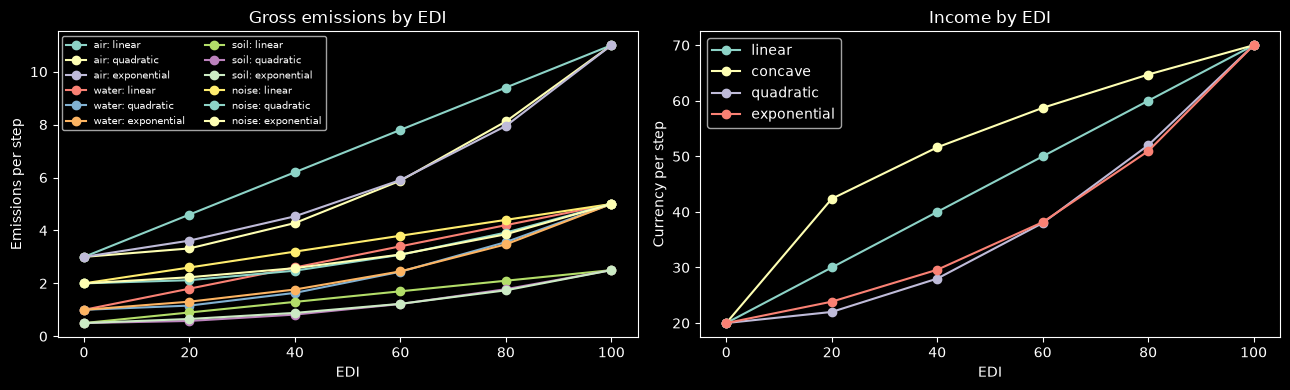

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for pollutant in POLLUTANTS:
    for shape in ("linear", "quadratic", "exponential"):
        values = [calculate_emissions(config, edi, pollutant, shape) for edi in EDI_LEVELS]
        axes[0].plot(EDI_LEVELS, values, marker="o", label=f"{pollutant}: {shape}")

axes[0].set_title("Gross emissions by EDI")
axes[0].set_xlabel("EDI")
axes[0].set_ylabel("Emissions per step")
axes[0].legend(fontsize=7, ncol=2)

for shape in CURVE_SHAPES:
    values = [calculate_income(config, edi, shape) for edi in EDI_LEVELS]
    axes[1].plot(EDI_LEVELS, values, marker="o", label=shape)

axes[1].set_title("Income by EDI")
axes[1].set_xlabel("EDI")
axes[1].set_ylabel("Currency per step")
axes[1].legend()

plt.tight_layout()

## 3. Compare fixed policies under candidate settings

In [9]:
EXTREME_SETTINGS = {
    "easy_probe": make_scenario(
        emission_multiplier=0.25,
        prevention_multiplier=1.15,
        prevention_cost_multiplier=0.5,
        cleanup_capacity_multiplier=1.25,
        cleanup_cost_multiplier=0.5,
        recovery_multiplier=1.15,
    ),
    "difficult_probe": make_scenario(
        emission_multiplier=3.0,
        prevention_multiplier=0.65,
        prevention_cost_multiplier=1.5,
        cleanup_capacity_multiplier=0.6,
        cleanup_cost_multiplier=1.5,
        recovery_multiplier=0.35,
    ),
}

In [10]:
extreme_results = pd.concat([evaluate_scenario(config, name, settings, SEEDS, STARTING_CURRENCY_LEVELS, DEVELOPMENT_TARGET) for name, settings in EXTREME_SETTINGS.items()], ignore_index=True)

In [11]:
endpoint_policy_summary = summarize_results(extreme_results)
display(endpoint_policy_summary.round(3))

,scenario,policy,scenario_runs,success_rate,survival_rate,failure_rate,mean_final_edi,mean_final_currency,mean_peak_pollution,mean_final_peak_pollution,mean_mitigation_spending,mean_income,mean_gross_emissions,mean_emissions_prevented,mean_cleanup_removed,mean_affordability_limited_actions,mean_capacity_shortfall_region_steps,affordability_constraint_observed_rate,cleanup_capacity_insufficient_rate,mean_failure_step
0,difficult_probe,growth_with_prevention,30,0.0,0.0,1.0,60.0,67.467,102.391,102.391,2757.500,4136.333,2832.767,623.477,0.000,78.767,0.000,0.967,0.000,24.933
1,difficult_probe,resource_aware,30,0.0,0.0,1.0,60.0,85.696,102.425,102.425,2551.250,4003.000,2733.833,498.280,57.370,82.533,0.300,1.000,0.267,24.267
2,difficult_probe,staged_adaptive,30,0.0,0.0,1.0,60.0,94.467,102.577,102.577,2549.500,4036.333,2758.567,533.246,33.231,82.433,0.133,1.000,0.133,24.433
3,easy_probe,growth_with_prevention,30,1.0,1.0,0.0,60.0,4739.029,13.087,5.148,19152.583,39217.667,7173.502,5959.082,0.000,36.467,0.000,0.000,0.000,NaN
4,easy_probe,resource_aware,30,1.0,1.0,0.0,60.0,4739.029,13.087,5.148,19152.583,39217.667,7173.502,5959.082,0.000,36.467,0.000,0.000,0.000,NaN
5,easy_probe,staged_adaptive,30,1.0,1.0,0.0,60.0,4739.029,13.087,5.148,19152.583,39217.667,7173.502,5959.082,0.000,36.467,0.000,0.000,0.000,NaN


Every policy reached mean final EDI 60 in both endpoint probes. The difference is environmental survival: the easy probe had 30 successes out of 30 per policy, while the difficult combined probe had 0 out of 30. The next summary adds episode peak pollution, which can reveal temporary spikes that final pollution misses.

In [12]:
endpoint_summary = extreme_results.groupby("scenario").agg(
    success_rate=("success", "mean"),
    survival_rate=("survived", "mean"),
    mean_final_edi=("final_mean_edi", "mean"),
    mean_failure_step=("failure_step", "mean"),
    mean_mitigation_spending=("mitigation_spending", "mean"),
)

display(endpoint_summary.round(3))

,success_rate,survival_rate,mean_final_edi,mean_failure_step,mean_mitigation_spending
scenario,,,,,
difficult_probe,0.0,0.0,60.0,24.544,2619.417
easy_probe,1.0,1.0,60.0,NaN,19152.583


### Endpoint result

Across policies, the easy probe had 100% success and survival. Its mean **episode peak** pollution was 13.09, while its mean final peak was only 5.15. This confirms why final pollution alone understated the worst load reached during the episode. The difficult combined probe had 0% success and survival, mean failure at step 24.54, and mean peak pollution 102.39. It combines 3 times the EDI-linked emissions with weaker prevention, higher costs, lower cleanup capacity, and weaker natural recovery.

## 4. Change one relationship at a time

The sweep isolates emissions magnitude and shape, income shape, development returns, mitigation price and capacity, and natural recovery. Each candidate changes one item from source defaults. Read the policy-specific rates before testing combinations.

In [13]:
ONE_FACTOR_SETTINGS = {}

for multiplier in (0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0, 4.0):
    name = f"emission_multiplier_{multiplier:g}"
    ONE_FACTOR_SETTINGS[name] = make_scenario(emission_multiplier=multiplier)

for shape in ("concave", "quadratic", "exponential"):
    ONE_FACTOR_SETTINGS[f"emissions_{shape}"] = make_scenario(emission_shape=shape)
    ONE_FACTOR_SETTINGS[f"income_{shape}"] = make_scenario(income_shape=shape)

for shape in ("linear", "quadratic"):
    ONE_FACTOR_SETTINGS[f"development_{shape}"] = make_scenario(development_shape=shape)

for multiplier in (0.5, 0.75, 1.0, 1.15):
    ONE_FACTOR_SETTINGS[f"prevention_effect_{multiplier:g}"] = make_scenario(prevention_multiplier=multiplier)

for multiplier in (0.5, 0.75, 1.0, 1.5, 2.0):
    ONE_FACTOR_SETTINGS[f"prevention_cost_{multiplier:g}"] = make_scenario(prevention_cost_multiplier=multiplier)
    ONE_FACTOR_SETTINGS[f"cleanup_cost_{multiplier:g}"] = make_scenario(cleanup_cost_multiplier=multiplier)

for multiplier in (0.5, 0.75, 1.0, 1.25, 1.5):
    ONE_FACTOR_SETTINGS[f"cleanup_capacity_{multiplier:g}"] = make_scenario(cleanup_capacity_multiplier=multiplier)

for multiplier in (0.25, 0.5, 0.75, 1.0, 1.25, 1.5):
    ONE_FACTOR_SETTINGS[f"recovery_{multiplier:g}"] = make_scenario(recovery_multiplier=multiplier)

one_factor_results = pd.concat([evaluate_scenario(config, name, settings, SEEDS, STARTING_CURRENCY_LEVELS, DEVELOPMENT_TARGET) for name, settings in ONE_FACTOR_SETTINGS.items()], ignore_index=True)

In [14]:
one_factor_summary = summarize_results(one_factor_results)
display(one_factor_summary.round(3))

,scenario,policy,scenario_runs,success_rate,survival_rate,failure_rate,mean_final_edi,mean_final_currency,mean_peak_pollution,mean_final_peak_pollution,mean_mitigation_spending,mean_income,mean_gross_emissions,mean_emissions_prevented,mean_cleanup_removed,mean_affordability_limited_actions,mean_capacity_shortfall_region_steps,affordability_constraint_observed_rate,cleanup_capacity_insufficient_rate,mean_failure_step
0,cleanup_capacity_0.5,growth_with_prevention,30,1.0,1.0,0.0,60.0,61.383,26.533,26.448,37822.333,39176.833,13080.123,9414.989,0.0,48.9,0.0,0.0,0.0,NaN
1,cleanup_capacity_0.5,resource_aware,30,1.0,1.0,0.0,60.0,61.383,26.533,26.448,37822.333,39176.833,13080.123,9414.989,0.0,48.9,0.0,0.0,0.0,NaN
2,cleanup_capacity_0.5,staged_adaptive,30,1.0,1.0,0.0,60.0,61.383,26.533,26.448,37822.333,39176.833,13080.123,9414.989,0.0,48.9,0.0,0.0,0.0,NaN
3,cleanup_capacity_0.75,growth_with_prevention,30,1.0,1.0,0.0,60.0,61.383,26.533,26.448,37822.333,39176.833,13080.123,9414.989,0.0,48.9,0.0,0.0,0.0,NaN
4,cleanup_capacity_0.75,resource_aware,30,1.0,1.0,0.0,60.0,61.383,26.533,26.448,37822.333,39176.833,13080.123,9414.989,0.0,48.9,0.0,0.0,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121,recovery_1.25,resource_aware,30,1.0,1.0,0.0,60.0,61.383,22.610,20.293,37822.333,39176.833,13080.123,9414.989,0.0,48.9,0.0,0.0,0.0,NaN
122,recovery_1.25,staged_adaptive,30,1.0,1.0,0.0,60.0,61.383,22.610,20.293,37822.333,39176.833,13080.123,9414.989,0.0,48.9,0.0,0.0,0.0,NaN
123,recovery_1.5,growth_with_prevention,30,1.0,1.0,0.0,60.0,61.383,20.577,16.343,37822.333,39176.833,13080.123,9414.989,0.0,48.9,0.0,0.0,0.0,NaN
124,recovery_1.5,resource_aware,30,1.0,1.0,0.0,60.0,61.383,20.577,16.343,37822.333,39176.833,13080.123,9414.989,0.0,48.9,0.0,0.0,0.0,NaN


Each candidate changes one setting from the source reference, with 30 matched seed-and-currency runs per policy. Success requires both surviving and reaching mean EDI 60, so check peak pollution and spending as well as success rate.

The sweep is a screening table: it shows which single changes matter, while the bisection below focuses on the emissions multiplier near the transition. The plotted bars show the policy-specific success rates.

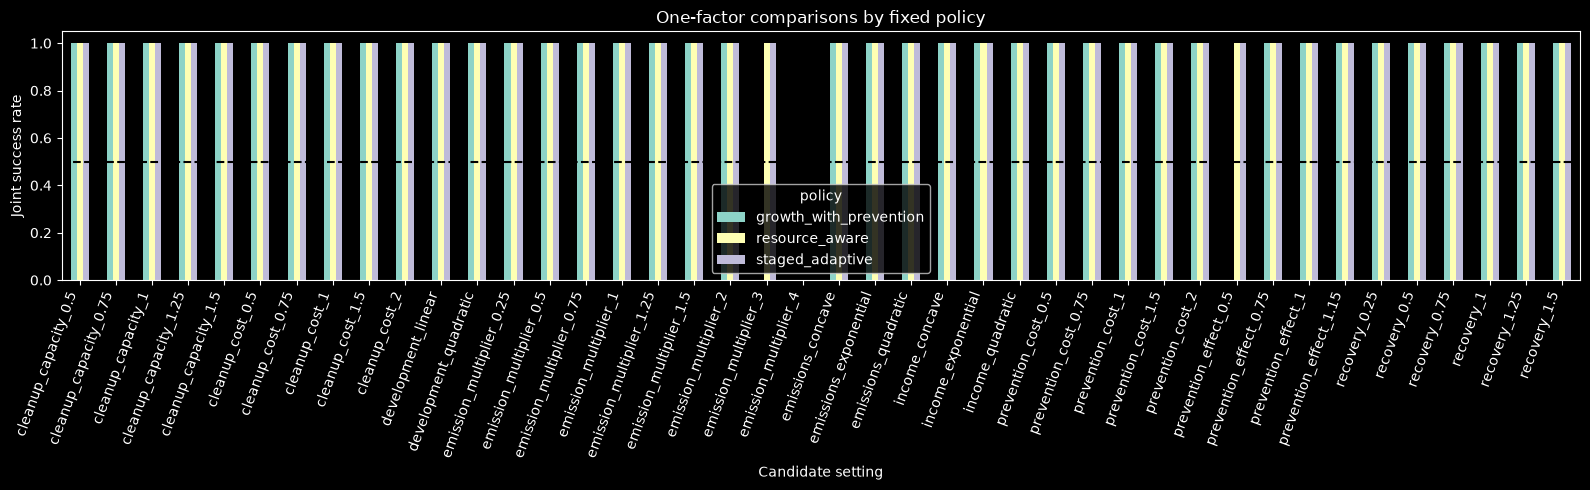

In [15]:
success_rates = one_factor_summary.pivot(index="scenario", columns="policy", values="success_rate")

success_rates.plot(kind="bar", figsize=(16, 5))
plt.axhline(0.5, color="black", linestyle="--")
plt.ylabel("Joint success rate")
plt.xlabel("Candidate setting")
plt.title("One-factor comparisons by fixed policy")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()

## 5. Narrow a monotonic 50/50 bracket

Use bisection only when the emissions multiplier sweep is monotonic and both endpoints bracket 50%. If not, use a denser grid and report the non-monotonic pattern rather than forcing a single balance point.

In [16]:
def run_emission_pressure(multiplier):
    settings = make_scenario(emission_multiplier=multiplier)
    return evaluate_scenario(config, f"emission_multiplier_{multiplier:.3f}", settings, SEEDS, STARTING_CURRENCY_LEVELS, DEVELOPMENT_TARGET)

In [17]:
low_pressure = 0.25
high_pressure = 4.0
low_results = run_emission_pressure(low_pressure)
high_results = run_emission_pressure(high_pressure)
low_success_rate = low_results["success"].mean()
high_success_rate = high_results["success"].mean()

if low_success_rate < 0.5 or high_success_rate > 0.5:
    print("These settings do not bracket 50%. Select endpoints from the sweep.")
else:
    bisection_rows = []
    for iteration in range(8):
        middle = (low_pressure + high_pressure) / 2
        middle_results = run_emission_pressure(middle)
        success_rate = middle_results["success"].mean()
        bisection_rows.append({
            "iteration": iteration + 1,
            "emission multiplier": middle,
            "success rate": success_rate,
            "survival rate": middle_results["survived"].mean(),
            "mean final EDI": middle_results["final_mean_edi"].mean(),
        })
        if success_rate >= 0.5:
            low_pressure = middle
        else:
            high_pressure = middle

    display(pd.DataFrame(bisection_rows).round(4))

,iteration,emission multiplier,success rate,survival rate,mean final EDI
0,1,2.1250,1.0000,1.0000,60.0
1,2,3.0625,0.6667,0.6667,60.0
2,3,3.5312,0.2222,0.2222,60.0
3,4,3.2969,0.3333,0.3333,60.0
4,5,3.1797,0.3333,0.3333,60.0
5,6,3.1211,0.4778,0.4778,60.0
6,7,3.0918,0.6667,0.6667,60.0
7,8,3.1064,0.6556,0.6556,60.0


### Bisection result

The saved search places the transition between multiplier 3.1064, with 65.56% success, and 3.1211, with 47.78% success. Lower emissions pressure had the higher success rate. This is an approximate boundary for the emissions multiplier alone, with other settings fixed at source values and under this seed, starting-currency, and policy cohort. It is not the result for the combined difficult probe.

## 6. Compare combinations and validate

In [ ]:
COMBINATIONS = {"convex_emissions_concave_income": make_scenario(emission_shape="quadratic", income_shape="concave"),
    "convex_emissions_lower_prevention_cost": make_scenario(emission_shape="quadratic", prevention_cost_multiplier=0.75),
    "exponential_emissions_stronger_prevention": make_scenario(emission_shape="exponential", prevention_multiplier=1.15),
    "higher_emissions_and_income": make_scenario(emission_multiplier=1.5, income_multiplier=1.5),
    }

combination_results = pd.concat([evaluate_scenario(config, name, settings, SEEDS, STARTING_CURRENCY_LEVELS, DEVELOPMENT_TARGET) for name, settings in COMBINATIONS.items()], ignore_index=True)

combination_summary = summarize_results(combination_results)
display(combination_summary.round(3))

### Combination table

All four candidates succeeded in all 30 runs per policy, so these combinations did not locate the failure boundary. Their pollution and cost outcomes differ: exponential emissions with stronger prevention had the lowest mean episode peak (16.36) at 37,822 mean mitigation spending.

Quadratic emissions with lower prevention cost had a mean peak of 18.32 and the lowest spending (28,549). Higher emissions plus higher income had the highest mean peak (39.23). The `final_peak_pollutant_load` values are lower than episode peaks when a region had a temporary spike followed by recovery.

In [ ]:
VALIDATION_SEEDS = tuple(range(20_000, 20_050))
VALIDATION_CURRENCY = (100, 250, 500, 750, 1000)
VALIDATION_SETTINGS = {"current_reference": make_scenario(), **COMBINATIONS}

validation_results = pd.concat([
    evaluate_scenario(config, name, settings, VALIDATION_SEEDS, VALIDATION_CURRENCY, DEVELOPMENT_TARGET) for name, settings in VALIDATION_SETTINGS.items()], ignore_index=True)

validation_summary = summarize_results(validation_results)
display(validation_summary.round(3))

### Validation summary

All five validation settings, including the current reference, had 100% success and survival across 250 episodes per policy. Every policy ended at mean EDI 60 because its rule stops development there. This larger validation therefore confirms the selected moderate candidates are stable for this cohort, but it does not validate continued growth beyond 60 or identify a 50/50 candidate.

In [ ]:
validation_metrics = [
    "final_air",
    "final_water",
    "final_soil",
    "final_noise",
    "failure_step",
    "final_mean_edi",
    "final_mean_currency",
    "income_total",
    "prevention_spending",
    "cleanup_spending",
    "gross_emissions",
    "invalid_region_steps",
]

validation_metric_summary = validation_results.groupby(["scenario", "policy"])[validation_metrics].agg(["mean", "std"]).round(2)
display(validation_metric_summary)

Across 250 runs per policy, all five validation settings had 100% success and survival at target EDI 60. The final formula summary reports a mean episode peak of 26.54 and mitigation spending of 37,835.70 for the source reference. Exponential emissions with stronger prevention averaged a 16.63 peak at 37,835.70 spending; quadratic emissions with lower prevention cost averaged an 18.35 peak at 28,591.02 spending. These summaries cover the tested policies, seeds, and cash tiers. The detailed per-pollutant table has no saved display, so its final-stock values cannot be checked here.

In [ ]:
success_by_currency = validation_results.pivot_table(index=["scenario", "policy"], columns="starting_currency_tier", values="success", aggfunc="mean")
display(success_by_currency.style.format("{:.1%}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1))

The saved final summary shows 100% success overall for these validation settings, but the starting-currency pivot has no saved display. The code computes success by starting-currency tier; the per-tier claim cannot be checked from the saved outputs in this notebook.

## Which equations are varied

The candidate curve shapes change the EDI-linked emissions term; baseline emissions stay fixed. Separate candidates change the income curve and the development-gain rule. Prevention effectiveness, prevention price, cleanup capacity, cleanup price, and natural recovery are currently tested by multiplying their source values.

The endpoint probes and one-factor sweep show that outcomes depend on both emissions pressure and policy. The approximate transition near multiplier 3.12 comes from the target-60 cohort; the next sections check how liquidity and higher development targets change that result. The validation policies stop at EDI 60, so they do not test maintaining higher targets.

## 7. Compare the full EDI range and development targets

This table compares gross emissions, income, high-prevention and high-cleanup costs, and cash remaining at every 10 EDI points. The affordability columns separate income-only affordability from the actual pre-income check: in the simulator, a region must have the investment and development costs in hand before that step's income is credited.

In [ ]:
FULL_EDI_LEVELS = tuple(range(0, 101, 10))
AFFORDABILITY_CASH_LEVELS = (100, 500, 1000)
HIGH_PREVENTION_LEVEL = 3
HIGH_CLEANUP_LEVEL = 3

In [22]:
edi_affordability_rows = []
for edi, starting_cash in product(FULL_EDI_LEVELS, AFFORDABILITY_CASH_LEVELS):
    income = calculate_income(config, edi)
    gross_emissions = sum(calculate_emissions(config, edi, pollutant) for pollutant in POLLUTANTS)
    prevention_cost = config.prevention_costs[HIGH_PREVENTION_LEVEL]
    prevention_fraction = config.prevention_fractions[HIGH_PREVENTION_LEVEL]
    cleanup_cost = config.cleanup_costs[HIGH_CLEANUP_LEVEL]
    cleanup_capacity = config.cleanup_capacities[HIGH_CLEANUP_LEVEL]
    development_cost = config.development_cost if edi < 100 else 0

    edi_affordability_rows.append({
        "EDI": edi,
        "starting cash": starting_cash,
        "gross emissions / region / step": gross_emissions,
        "income / region / step": income,
        "high prevention cost": prevention_cost,
        "emissions prevented by high prevention": gross_emissions * prevention_fraction,
        "income less prevention cost": income - prevention_cost,
        "high cleanup cost": cleanup_cost,
        "cleanup capacity / pollutant": cleanup_capacity,
        "income less cleanup cost": income - cleanup_cost,
        "cash after income": starting_cash + income,
        "prevention + development affordable before income": (starting_cash >= prevention_cost + development_cost),
        "cleanup + development affordable before income": (starting_cash >= cleanup_cost + development_cost),
        "cash after income and prevention + development": (starting_cash + income - prevention_cost - development_cost),
    })

affordability_by_edi = pd.DataFrame(edi_affordability_rows)
display(affordability_by_edi.round(2))

,EDI,starting cash,gross emissions / region / step,income / region / step,high prevention cost,emissions prevented by high prevention,income less prevention cost,high cleanup cost,cleanup capacity / pollutant,income less cleanup cost,cash after income,prevention + development affordable before income,cleanup + development affordable before income,cash after income and prevention + development
0,0,100,6.5,20.0,50.0,4.88,-30.0,80.0,10.0,-60.0,120.0,False,False,-30.0
1,0,500,6.5,20.0,50.0,4.88,-30.0,80.0,10.0,-60.0,520.0,True,True,370.0
2,0,1000,6.5,20.0,50.0,4.88,-30.0,80.0,10.0,-60.0,1020.0,True,True,870.0
3,10,100,8.2,25.0,50.0,6.15,-25.0,80.0,10.0,-55.0,125.0,False,False,-25.0
4,10,500,8.2,25.0,50.0,6.15,-25.0,80.0,10.0,-55.0,525.0,True,True,375.0
5,10,1000,8.2,25.0,50.0,6.15,-25.0,80.0,10.0,-55.0,1025.0,True,True,875.0
6,20,100,9.9,30.0,50.0,7.43,-20.0,80.0,10.0,-50.0,130.0,False,False,-20.0
7,20,500,9.9,30.0,50.0,7.43,-20.0,80.0,10.0,-50.0,530.0,True,True,380.0
8,20,1000,9.9,30.0,50.0,7.43,-20.0,80.0,10.0,-50.0,1030.0,True,True,880.0
9,30,100,11.6,35.0,50.0,8.70,-15.0,80.0,10.0,-45.0,135.0,False,False,-15.0


###  EDI and affordability table

Gross emissions and income are per region per step; emissions are summed over pollutants, while cleanup capacity is shown per pollutant. A positive income-minus-cost value means recurring income could cover that action after income arrives. It does not mean the action is affordable at the start of a step. The explicit cash check includes the selected starting balance and the development cost, so it shows when the timing rule can force a cheaper action even if average income looks adequate.

## 8. Validate targets and the 3.10 to 3.20 transition

The expanded cohort uses 50 shared seeds, three starting-currency tiers, and all three fixed policies. The fine sweep tests multipliers from 3.10 to 3.20 at target EDI 60. A second comparison tests targets 40, 60, 80, and 100 at 3.10, 3.15, and 3.20. This tests whether the apparent boundary shifts when development continues longer. The tables report pooled and policy-specific success, survival, peak pollution, spending, and failure timing.

In [23]:
TRANSITION_SEEDS = tuple(range(30_000, 30_050))
TRANSITION_CURRENCY = (100, 500, 1000)
TRANSITION_MULTIPLIERS = tuple(round(value, 2) for value in np.arange(3.10, 3.201, 0.01))
DEVELOPMENT_TARGETS = (40, 60, 80, 100)

transition_results = pd.concat([
    evaluate_scenario(config, f"emission_multiplier_{multiplier:.2f}_target_60", make_scenario(emission_multiplier=multiplier), TRANSITION_SEEDS, TRANSITION_CURRENCY,
        60) for multiplier in TRANSITION_MULTIPLIERS], ignore_index=True)

transition_summary = transition_results.groupby("scenario").agg(
    episodes=("success", "size"),
    success_rate=("success", "mean"),
    survival_rate=("survived", "mean"),
    mean_peak_pollution=("peak_pollutant_load", "mean"),
    mean_mitigation_spending=("mitigation_spending", "mean"),
    affordability_constraint_observed_rate=("failure_affordability_constrained", "mean"),
    cleanup_capacity_insufficient_rate=("failure_cleanup_capacity_limited", "mean"),
    mean_failure_step=("failure_step", "mean"),
).reset_index()
display(transition_summary.round(3))

,scenario,episodes,success_rate,survival_rate,mean_peak_pollution,mean_mitigation_spending,affordability_constraint_observed_rate,cleanup_capacity_insufficient_rate,mean_failure_step
0,emission_multiplier_3.10_target_60,450,0.667,0.667,76.998,34203.800,0.000,0.000,145.240
1,emission_multiplier_3.11_target_60,450,0.591,0.591,80.598,34081.100,0.076,0.000,153.886
2,emission_multiplier_3.12_target_60,450,0.491,0.491,82.506,33659.711,0.160,0.029,158.769
3,emission_multiplier_3.13_target_60,450,0.447,0.447,83.259,33116.133,0.211,0.033,157.209
4,emission_multiplier_3.14_target_60,450,0.444,0.444,83.858,32644.689,0.218,0.024,153.168
5,emission_multiplier_3.15_target_60,450,0.444,0.444,84.561,32261.111,0.209,0.027,149.736
6,emission_multiplier_3.16_target_60,450,0.402,0.402,85.151,31924.589,0.253,0.033,150.450
7,emission_multiplier_3.17_target_60,450,0.338,0.338,85.421,31555.067,0.316,0.040,152.520
8,emission_multiplier_3.18_target_60,450,0.333,0.333,85.461,31187.611,0.316,0.051,150.057
9,emission_multiplier_3.19_target_60,450,0.333,0.333,85.495,30867.333,0.318,0.062,147.630


In [24]:
transition_by_policy = transition_results.pivot_table(index="scenario", columns="policy", values="success", aggfunc="mean")
display(transition_by_policy.style.format("{:.1%}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1))

policy,growth_with_prevention,resource_aware,staged_adaptive
scenario,,,
emission_multiplier_3.10_target_60,0.0%,100.0%,100.0%
emission_multiplier_3.11_target_60,0.0%,100.0%,77.3%
emission_multiplier_3.12_target_60,0.0%,100.0%,47.3%
emission_multiplier_3.13_target_60,0.0%,100.0%,34.0%
emission_multiplier_3.14_target_60,0.0%,100.0%,33.3%
emission_multiplier_3.15_target_60,0.0%,100.0%,33.3%
emission_multiplier_3.16_target_60,0.0%,100.0%,20.7%
emission_multiplier_3.17_target_60,0.0%,100.0%,1.3%
emission_multiplier_3.18_target_60,0.0%,100.0%,0.0%


In [25]:
results = []
for target in DEVELOPMENT_TARGETS:
    for multiplier in (3.10, 3.15, 3.20):
        scenario = make_scenario(emission_multiplier=multiplier)
        scenario_name = f"emission_multiplier_{multiplier:.2f}_target_{target}"
        result = evaluate_scenario(config, scenario_name, scenario, TRANSITION_SEEDS, TRANSITION_CURRENCY, target)
        results.append(result)

target_validation_results = pd.concat(results, ignore_index=True)

,scenario,policy,episodes,success_rate,survival_rate,mean_final_edi,mean_peak_pollution,mean_mitigation_spending,affordability_constraint_observed_rate,cleanup_capacity_insufficient_rate,mean_failure_step
0,emission_multiplier_3.10_target_100,growth_with_prevention,150,0.000,0.000,78.580,102.407,1256.167,1.000,0.00,28.780
1,emission_multiplier_3.10_target_100,resource_aware,150,0.000,0.000,78.580,102.407,1256.167,1.000,0.00,28.780
2,emission_multiplier_3.10_target_100,staged_adaptive,150,0.000,0.000,78.580,102.407,1256.167,1.000,0.00,28.780
3,emission_multiplier_3.10_target_40,growth_with_prevention,150,0.000,0.000,40.000,100.335,28780.733,0.927,0.00,179.773
4,emission_multiplier_3.10_target_40,resource_aware,150,1.000,1.000,40.000,52.909,31989.267,0.000,0.00,NaN
5,emission_multiplier_3.10_target_40,staged_adaptive,150,1.000,1.000,40.000,67.855,31977.967,0.000,0.00,NaN
6,emission_multiplier_3.10_target_60,growth_with_prevention,150,0.000,0.000,60.000,100.322,26931.167,0.000,0.00,145.240
7,emission_multiplier_3.10_target_60,resource_aware,150,1.000,1.000,60.000,54.722,37855.733,0.000,0.00,NaN
8,emission_multiplier_3.10_target_60,staged_adaptive,150,1.000,1.000,60.000,75.950,37824.500,0.000,0.00,NaN
9,emission_multiplier_3.10_target_80,growth_with_prevention,150,0.000,0.000,77.740,101.874,3906.567,0.667,0.00,41.120


In [ ]:
target_validation_summary = target_validation_results.groupby(["scenario", "policy"]).agg(episodes=("success", "size"),
    success_rate=("success", "mean"),
    survival_rate=("survived", "mean"),
    mean_final_edi=("final_mean_edi", "mean"),
    mean_peak_pollution=("peak_pollutant_load", "mean"),
    mean_mitigation_spending=("mitigation_spending", "mean"),
    affordability_constraint_observed_rate=("failure_affordability_constrained", "mean"),
    cleanup_capacity_insufficient_rate=("failure_cleanup_capacity_limited", "mean"),
    mean_failure_step=("failure_step", "mean"),
).reset_index()
display(target_validation_summary.round(3))

In [26]:
pooled_transition = transition_results.groupby("scenario")["success"].mean()
closest_to_half = (pooled_transition - 0.5).abs().sort_values().head(1)
print("Closest tested multiplier to a 50% pooled success rate:")
display(transition_summary[transition_summary["scenario"].isin(closest_to_half.index)].round(3))

Closest tested multiplier to a 50% pooled success rate:


,scenario,episodes,success_rate,survival_rate,mean_peak_pollution,mean_mitigation_spending,affordability_constraint_observed_rate,cleanup_capacity_insufficient_rate,mean_failure_step
2,emission_multiplier_3.12_target_60,450,0.491,0.491,82.506,33659.711,0.16,0.029,158.769


The closest pooled result to 50% was multiplier 3.12: 49.1% success and survival across 450 runs (50 seeds, three cash tiers, and three policies). The policy rates show that this is not a shared balance point: growth-with-prevention succeeded in 0%, resource-aware in 100%, and staged-adaptive in 47.3%. Resource-aware remained at 100% through multiplier 3.20, while growth-with-prevention was at 0% across the grid; staged-adaptive fell from 100% at 3.10 to 0% at 3.20. The 3.12 result is a useful transition for staged-adaptive, but it does not show the equations create the same tradeoff for each reasonable policy.

Across all policies at target 60, success falls from 66.7% at 3.10 to 33.3% at 3.20. Mean episode peak rises from 77.0 to 85.5, while average mitigation spending falls from 34,204 to 30,563. That spending drop mostly reflects more episodes ending early, so it should not be read as improved efficiency. Mean failures occur around steps 145 to 159, later than the difficult endpoint's step 24.5.

The target comparison shows a strong interaction with policy and growth horizon. At target 40, resource-aware and staged-adaptive succeeded in all runs at all three multipliers, while growth-with-prevention failed in all runs. At target 60, resource-aware again succeeded in all runs, but staged-adaptive was mixed at 3.15 and failed all runs at 3.20. At targets 80 and 100, all policies failed before completing the episode; mean final EDI was about 77 to 79, so the regions often failed before reaching those targets. A near-50% pooled rate should always be reported alongside per-policy and per-target rates.

## 9. Check why fixed policies can match

The policies use different pollution-pressure cutoffs for switching from prevention to cleanup. Below their cutoffs, they can choose the same investment; affordability fallbacks can make their chosen actions match above the cutoff as well.

In [27]:
def action_signature(episode):
    trace = pd.DataFrame(episode["trajectory"])
    return tuple(zip(
        trace["step"],
        trace["region"],
        trace["selected_investment"],
        trace["edi_before"],
        trace["edi_after"],
    ))

In [28]:
def first_action_divergence(seed, cash):
    traces = {}

    for policy in POLICY_NAMES:
        trajectory = policy_probe_runs[(seed, cash, policy)]["trajectory"]
        traces[policy] = pd.DataFrame(trajectory)

    columns = ["step", "region", "selected_investment", "edi_after"]
    joined = traces[POLICY_NAMES[0]][columns].copy()

    joined = joined.rename(columns={"selected_investment": "investment_a", "edi_after": "edi_after_a"})

    for number, policy in enumerate(POLICY_NAMES[1:], start=1):
        policy_trace = traces[policy][columns].copy()

        policy_trace = policy_trace.rename(columns={"selected_investment": f"investment_{number}", "edi_after": f"edi_after_{number}"})
        joined = joined.merge(policy_trace, on=["step", "region"], how="outer")

    investment_columns = []
    edi_columns = []

    for column in joined.columns:
        if column.startswith("investment_"):
            investment_columns.append(column)

        if column.startswith("edi_after_"):
            edi_columns.append(column)

    investment_divergence = joined[investment_columns].nunique(axis=1) > 1
    edi_divergence = joined[edi_columns].nunique(axis=1) > 1

    divergent = joined[investment_divergence | edi_divergence]

    return divergent.head(1)

In [29]:
POLICY_PROBE_SEEDS = (31_001, 31_002, 31_003, 31_004, 31_005)
POLICY_PROBE_CASH = (100, 500, 1000)
POLICY_PROBE_MULTIPLIER = 3.15
POLICY_NAMES = ("growth_with_prevention", "staged_adaptive", "resource_aware")
policy_probe_rows = []
policy_probe_runs = {}

for seed, cash, policy in product(POLICY_PROBE_SEEDS, POLICY_PROBE_CASH, POLICY_NAMES):
    episode = run_episode(config, policy, seed, cash, make_scenario(emission_multiplier=POLICY_PROBE_MULTIPLIER), 60, record_trace=True)
    policy_probe_runs[(seed, cash, policy)] = episode

    policy_probe_rows.append({
        "seed": seed,
        "starting cash": cash,
        "policy": policy,
        "success": episode["success"],
        "failure step": episode["failure_step"],
        "affordability-limited actions": episode["affordability_limited_actions"],
        "action counts": episode["action_counts"],
        "action trace": episode["trajectory"],
    })

policy_probe = pd.DataFrame(policy_probe_rows)

,seed,starting cash,all action traces identical,all outcomes identical
0,31001,100,False,False
1,31001,500,False,False
2,31001,1000,False,False
3,31002,100,False,False
4,31002,500,False,False
5,31002,1000,False,False
6,31003,100,False,False
7,31003,500,False,False
8,31003,1000,False,False
9,31004,100,False,False


In [ ]:
match_rows = []
for seed, cash in product(POLICY_PROBE_SEEDS, POLICY_PROBE_CASH):
    episodes = [policy_probe_runs[(seed, cash, policy)] for policy in POLICY_NAMES]
    signatures = [action_signature(episode) for episode in episodes]
    match_rows.append({
        "seed": seed,
        "starting cash": cash,
        "all action traces identical": len(set(signatures)) == 1,
        "all outcomes identical": len({(episode["success"], episode["failure_step"], episode["final_mean_edi"]) for episode in episodes}) == 1,
    })

display(pd.DataFrame(match_rows))

In [30]:
print("First divergence for one matched start (empty means identical through the episode):")
display(first_action_divergence(POLICY_PROBE_SEEDS[0], POLICY_PROBE_CASH[1]))

First divergence for one matched start (empty means identical through the episode):


,step,region,investment_a,edi_after_a,investment_1,edi_after_1,investment_2,edi_after_2
116,30,0,prevent_high,60.0,prevent_high,60.0,prevent_medium,60.0


### What matching policy outcomes mean

In the easy endpoint, all three policies had identical outcome metrics because their pressure thresholds did not change their actions: each continued high prevention. In the 15 matched starts tested near multiplier 3.15, none had identical full action traces or identical outcomes across all three policies. For the inspected seed and 500 cash tier, the first action difference appeared at step 30: growth-with-prevention and staged-adaptive selected high prevention, while resource-aware selected medium prevention. The policy-level transition table shows the consequence: resource-aware survived every tested multiplier through 3.20, while the always-prevention policy failed throughout.

The per-step trace includes preferred and selected investment, cash before and after income, emissions prevention, cleanup capacity and efficiency, and pollutant stock before and after cleanup. Episode constraint flags indicate that an unaffordable preferred action or insufficient selected cleanup capacity was observed at the failure step; they are evidence for diagnosis, not proof that one flag alone caused the failure.

## 10. Visualize matched success and failure episodes

The next cell selects a multiplier in the expanded transition cohort that produced both successes and failures, then chooses one episode of each outcome with the same starting-cash tier where possible. It plots regional means over time for EDI, currency, income and mitigation costs, and pollutant stocks. A horizontal pollution-limit line marks the environmental failure threshold. The plotted examples are illustrative; the tables above provide the rates across all tested scenarios.

In [36]:
comparison_results = transition_results.copy()

comparison_results["emission_multiplier"] = comparison_results["scenario"].str.split("_").str[2].astype(float)
comparison_results["development_target"] = comparison_results["scenario"].str.split("_").str[-1].astype(int)

matching_columns = ["seed", "starting_currency_tier", "policy", "development_target"]

successes = comparison_results[comparison_results["success"]]
failures = comparison_results[comparison_results["failed"]]

matched_cases = successes.merge(failures, on=matching_columns, suffixes=("_success", "_failure"))

matched_cases = matched_cases[matched_cases["emission_multiplier_success"] != matched_cases["emission_multiplier_failure"]].copy()

matched_cases["multiplier_difference"] = (matched_cases["emission_multiplier_success"] - matched_cases["emission_multiplier_failure"]).abs()

matched_cases = matched_cases.sort_values("multiplier_difference")

if matched_cases.empty:
    print("No matched success/failure cases found. Consider expanding the multiplier grid.")
else:
    selected_match = matched_cases.iloc[0]

    print(f"Policy: {selected_match['policy']}")
    print(f"Seed: {selected_match['seed']}")
    print(f"Initial currency: {selected_match['starting_currency_tier']}")
    print(f"EDI target: {selected_match['development_target']}")
    print(f"Success multiplier: {selected_match['emission_multiplier_success']:.2f}")
    print(f"Failure multiplier: {selected_match['emission_multiplier_failure']:.2f}")

Policy: staged_adaptive
Seed: 30001
Initial currency: 100
EDI target: 60
Success multiplier: 3.10
Failure multiplier: 3.11


In [37]:
trace_cases = []

if not matched_cases.empty:
    selected_cases = (("Success", selected_match["emission_multiplier_success"]), ("Failure", selected_match["emission_multiplier_failure"]))

    for label, multiplier in selected_cases:
        scenario = make_scenario(emission_multiplier=float(multiplier))

        episode = run_episode(
            config,
            selected_match["policy"],
            int(selected_match["seed"]),
            int(selected_match["starting_currency_tier"]),
            scenario,
            int(selected_match["development_target"]),
            record_trace=True,
        )

        frame = pd.DataFrame(episode["trajectory"])
        normalized_pollutant_columns = []

        for pollutant in POLLUTANTS:
            ratio_column = f"pollution_ratio_{pollutant}"
            pollution_column = f"pollution_after_{pollutant}"

            frame[ratio_column] = frame[pollution_column] / config.pollution_limits[pollutant]
            normalized_pollutant_columns.append(ratio_column)

        summary = frame.groupby("step").agg(
            edi=("edi_after", "mean"),
            currency=("currency_after", "mean"),
            income=("income", "mean"),
            mitigation_cost=("mitigation_cost", "mean"),
        )

        maximum_pollution = frame.groupby("step")[normalized_pollutant_columns].max()
        summary["maximum pollutant load / limit"] = maximum_pollution.max(axis=1)

        trace_cases.append((label, multiplier, episode, summary))

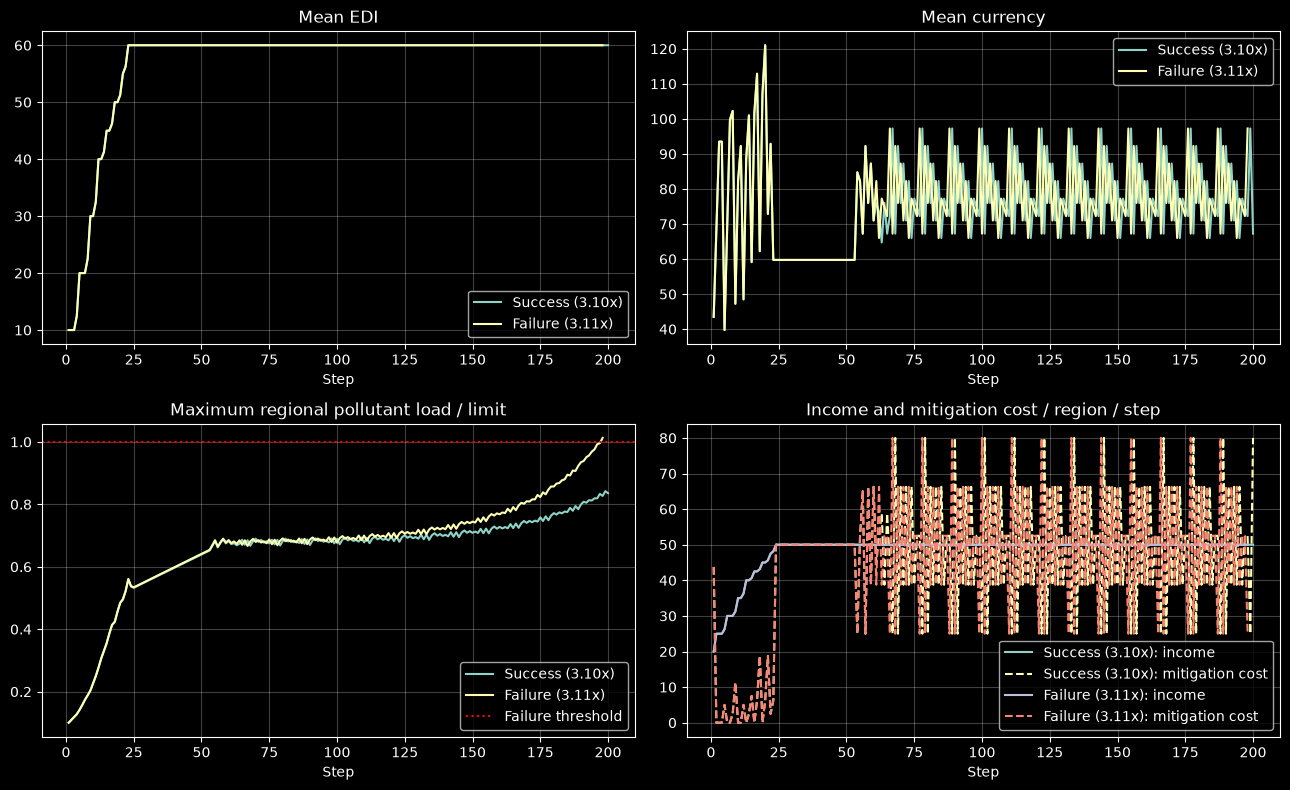

In [38]:
if trace_cases:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))

    metrics = (
        ("edi", "Mean EDI"),
        ("currency", "Mean currency"),
        ("maximum pollutant load / limit", "Maximum regional pollutant load / limit"),
        ("income", "Income and mitigation cost / region / step"),
    )

    for axis, (metric, title) in zip(axes.flat, metrics):
        for label, multiplier, episode, summary in trace_cases:
            case_label = f"{label} ({multiplier:.2f}x)"

            if metric == "income":
                axis.plot(summary.index, summary["income"], label=f"{case_label}: income")
                axis.plot(summary.index, summary["mitigation_cost"], linestyle="--", label=f"{case_label}: mitigation cost")
            else:
                axis.plot(summary.index, summary[metric], label=case_label)

        if metric == "maximum pollutant load / limit":
            axis.axhline(1.0, color="red", linestyle=":", label="Failure threshold")

        axis.set_title(title)
        axis.set_xlabel("Step")
        axis.grid(alpha=0.25)
        axis.legend()

    plt.tight_layout()
    plt.show()
else:
    print("No matched trajectories available for plotting.")


In [39]:
comparison_rows = []

for label, multiplier, episode, summary in trace_cases:
    comparison_row = {
        "outcome": label,
        "policy": selected_match["policy"],
        "seed": selected_match["seed"],
        "starting currency tier": selected_match["starting_currency_tier"],
        "EDI target": selected_match["development_target"],
        "emission multiplier": multiplier,
        "failure step": episode["failure_step"],
        "peak pollution": episode["peak_pollutant_load"],
        "mitigation spending": episode["mitigation_spending"],
    }

    comparison_rows.append(comparison_row)

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(3))


,outcome,policy,seed,starting currency tier,EDI target,emission multiplier,failure step,peak pollution,mitigation spending
0,Success,staged_adaptive,30001,100,60,3.10,NaN,84.202,35915.0
1,Failure,staged_adaptive,30001,100,60,3.11,198.0,101.273,35395.0


### Reading the episode plots

The paired examples use seed 30000 and the 100 starting-currency tier, so their initial regional cash values match. Under the selected near-transition multiplier, resource-aware succeeded with peak pollution 58.05 and mitigation spending 35,620. Growth-with-prevention failed at step 121 with peak pollution 100.60 after spending 19,900. This illustrates how policy choice changes both environmental outcome and cumulative spending even when the initial conditions match. It is one example, not an estimate of the average treatment effect; use the policy table for cohort rates.

## 11. Final results by formula candidate

This final table combines the one-factor sweep, selected combinations, expanded validation, and endpoint probes. Each row aggregates the matching seed, starting-currency, and fixed-policy runs for that candidate. The formula family identifies which relationship changed; the scenario name identifies the exact shape or parameter setting.

In [40]:
def formula_family(name):
    if name in ("easy_probe", "difficult_probe"):
        return "Extreme endpoint"
    if name == "current_reference":
        return "Source reference"
    if name.startswith("emission_multiplier_"):
        return "Emissions magnitude"
    if name.startswith("emissions_"):
        return "Emissions shape"
    if name.startswith("income_"):
        return "Income shape"
    if name.startswith("development_"):
        return "Development returns"
    if name.startswith("prevention_effect_"):
        return "Prevention effectiveness"
    if name.startswith("prevention_cost_"):
        return "Prevention cost"
    if name.startswith("cleanup_cost_"):
        return "Cleanup cost"
    if name.startswith("cleanup_capacity_"):
        return "Cleanup capacity"
    if name.startswith("recovery_"):
        return "Natural recovery"
    if name in (
        "convex_emissions_concave_income",
        "convex_emissions_lower_prevention_cost",
        "exponential_emissions_stronger_prevention",
        "higher_emissions_and_income",
    ):
        return "Combined candidate"
    return "Other"

In [41]:
all_formula_results = pd.concat([
    one_factor_results.assign(experiment_group="One-factor"),
    combination_results.assign(experiment_group="Combination"),
    validation_results.assign(experiment_group="Validation"),
    extreme_results.assign(experiment_group="Endpoint"),
    transition_results.assign(experiment_group="Transition validation"),
    target_validation_results.assign(experiment_group="Development targets"),
], ignore_index=True)

all_formula_results["formula_family"] = (all_formula_results["scenario"].map(formula_family))

formula_result_summary = all_formula_results.groupby(["experiment_group", "formula_family", "scenario"]).agg(
    episodes=("success", "size"),
    success_rate=("success", "mean"),
    survival_rate=("survived", "mean"),
    mean_final_edi=("final_mean_edi", "mean"),
    mean_peak_pollution=("peak_pollutant_load", "mean"),
    mean_gross_emissions=("gross_emissions", "mean"),
    mean_mitigation_spending=("mitigation_spending", "mean"),
    affordability_constraint_observed_rate=("failure_affordability_constrained", "mean"),
    cleanup_capacity_insufficient_rate=("failure_cleanup_capacity_limited", "mean"),
    mean_final_currency=("final_mean_currency", "mean"),
    mean_failure_step=("failure_step", "mean"),
).reset_index()

In [42]:
formula_result_summary = formula_result_summary.sort_values(["experiment_group", "formula_family", "scenario"])
display(formula_result_summary.round(3))

,experiment_group,formula_family,scenario,episodes,success_rate,survival_rate,mean_final_edi,mean_peak_pollution,mean_gross_emissions,mean_mitigation_spending,affordability_constraint_observed_rate,cleanup_capacity_insufficient_rate,mean_final_currency,mean_failure_step
0,Combination,Combined candidate,convex_emissions_concave_income,90,1.0,1.0,60.00,17.667,9902.761,38404.833,0.0,0.0,1712.656,NaN
1,Combination,Combined candidate,convex_emissions_lower_prevention_cost,90,1.0,1.0,60.00,18.317,9871.025,28549.125,0.0,0.0,2385.144,NaN
2,Combination,Combined candidate,exponential_emissions_stronger_prevention,90,1.0,1.0,60.00,16.363,9930.639,37822.333,0.0,0.0,61.383,NaN
3,Combination,Combined candidate,higher_emissions_and_income,90,1.0,1.0,60.00,39.232,17060.560,38276.000,0.0,0.0,2874.758,NaN
4,Development targets,Emissions magnitude,emission_multiplier_3.10_target_100,450,0.0,0.0,78.58,102.407,3824.604,1256.167,1.0,0.0,98.143,28.78
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,Validation,Combined candidate,convex_emissions_concave_income,750,1.0,1.0,60.00,17.633,9905.925,38424.480,0.0,0.0,1709.820,NaN
72,Validation,Combined candidate,convex_emissions_lower_prevention_cost,750,1.0,1.0,60.00,18.347,9878.636,28591.020,0.0,0.0,2380.962,NaN
73,Validation,Combined candidate,exponential_emissions_stronger_prevention,750,1.0,1.0,60.00,16.625,9935.585,37835.700,0.0,0.0,62.302,NaN
74,Validation,Combined candidate,higher_emissions_and_income,750,1.0,1.0,60.00,39.240,17070.556,38300.360,0.0,0.0,2874.697,NaN


### How to use the final table

Compare success and survival first, then final EDI, episode peak pollution, mitigation spending, and the two observed failure-constraint rates. The endpoint rows show easy and difficult bounds; one-factor rows isolate equations; the transition and target rows show how outcomes depend on the emissions multiplier, development target, and fixed policy.

The pooled 49.1% rate at multiplier 3.12 is not a policy-robust balance: it combines 0% success for growth-with-prevention, 100% for resource-aware, and 47.3% for staged-adaptive. The simulator and policies are fixed-policy research probes; they do not establish an optimal policy or a universal equation balance. The policies stop at their selected EDI targets, and the non-emissions stock equations remain fixed.